# Backlog v2 — calibration, exposure and ensemble evidence

Read `docs/SPAN_002_PROTOCOL.md` and `docs/SPAN_002_RESULTS.md` for the predeclared
contract and decisions. The completed span accepts the continued classifier as a
local research reference; its official verification remains future work. All development
data have been inspected; confirmation is unused. Local log loss is not a new
official Kaggle score. Best official loss remains 0.97025 unless separately updated.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO=Path.cwd().resolve()
if not (REPO/'GOAL.md').exists(): REPO=REPO.parent
assert (REPO/'GOAL.md').exists()
RESULTS=REPO/'results/span_002'
HEAVY=Path.home()/'database/llm_classification_finetuning/runs/span_002'
FIGURES=HEAVY/'figures';FIGURES.mkdir(parents=True,exist_ok=True)
def read(name): return json.loads((RESULTS/name).read_text())
def save(fig,name):
    for extension in ['png','svg']:
        fig.savefig(FIGURES/(name+'.'+extension),bbox_inches='tight',dpi=160)
    plt.show()

plan=read('span_plan.json')
registry=json.loads((REPO/'backlog/hypotheses.json').read_text())
v2=next(v for v in registry['versions'] if v['number']==2)
records={item['id']:item for item in registry['items']}
display(pd.DataFrame([{'task':key,'title':records[key]['title'],'status':records[key]['status']}
                      for key in v2['focus_ids']]))
print('v2 state:',v2['state'],'original start:',plan['started_at'],'deadline:',plan['deadline'])
print('GPU cap:',plan['gpu_session_seconds_cap']/3600,'elapsed two-T4 session-hours')


,task,title,status
0,H40,Constrained probability calibration,done
1,E01,Instrument accepted optimizer updates and trai...,done
2,H03,Complete training exposure,done
3,H37,Diverse preference-model ensemble,done
4,H42,Preserve tie information during paired-order a...,done


v2 state: closed original start: 2026-11-03T18:23:46+00:00 deadline: 2026-11-05T18:23:46+00:00
GPU cap: 12.0 elapsed two-T4 session-hours


## H40: small symmetric calibration

Five outer prompt-grouped folds; three grouped inner folds select among declared
families. The nested selector is primary. Each interval compares identical rows;
intervals condition on fitted OOF predictions and have no multiplicity guarantee.


,cohort,model,calibration,rows,log_loss,accuracy,tie_loss,tie_auc
0,full_baseline,frozen,temperature,5746,0.968872,0.527323,1.001286,0.667578
1,full_baseline,frozen,temperature_tie,5746,0.967179,0.531674,1.082651,0.667597
2,full_baseline,frozen,symmetric_vector,5746,0.967607,0.532196,1.082752,0.667507
3,full_baseline,frozen,nested_selected,5746,0.967740,0.532022,1.082821,0.667413
4,paired_pilot,frozen,temperature,1024,0.977479,0.522461,1.026904,0.659103
5,paired_pilot,frozen,temperature_tie,1024,0.976986,0.519531,1.074192,0.659041
6,paired_pilot,frozen,symmetric_vector,1024,0.977297,0.518555,1.073968,0.659664
7,paired_pilot,frozen,nested_selected,1024,0.976986,0.519531,1.074192,0.659041
8,paired_pilot,paired_ce,temperature,1024,0.978105,0.515625,1.152241,0.658131
9,paired_pilot,paired_ce,temperature_tie,1024,0.976984,0.517578,1.076027,0.657923


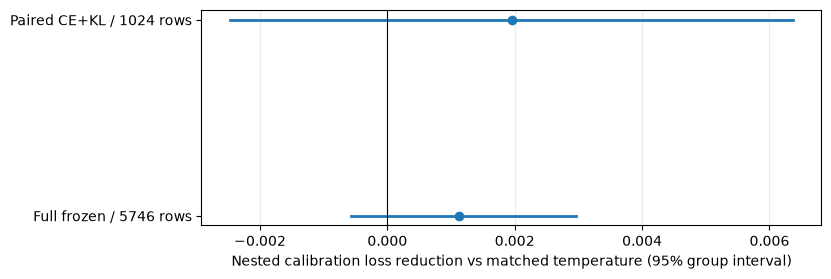

H42 practical stopping gate: {'overall_loss_gap': -0.00015099503594040442, 'tie_class_loss_gap': 0.0015366018961533445, 'calibration_resolves_deficit': True, 'interpretation': 'Predeclared practical stopping rule, not an equivalence test.'}
This gate does not prove equivalence or improved tie discrimination.


In [2]:
cal=read('calibration_results.json')
rows=[]
for cohort,entry in cal['cohorts'].items():
    for model,result in entry['models'].items():
        for family,metric in result['families'].items():
            rows.append({'cohort':cohort,'model':model,'calibration':family,
                         'rows':metric['rows'],'log_loss':metric['log_loss'],
                         'accuracy':metric['accuracy'],'tie_loss':metric['class_loss'][2],
                         'tie_auc':metric['tie_auc']})
display(pd.DataFrame(rows))
comparisons=[('Full frozen / 5746 rows',cal['cohorts']['full_baseline']['models']['frozen']['nested_gain_vs_temperature']),
             ('Paired CE+KL / 1024 rows',cal['cohorts']['paired_pilot']['models']['paired_kl']['nested_gain_vs_temperature'])]
fig,ax=plt.subplots(figsize=(8,2.8))
for index,(label,result) in enumerate(comparisons):
    lo,hi=result['interval_95']
    ax.plot([lo,hi],[index,index],color='C0',linewidth=2)
    ax.scatter([result['gain']],[index],color='C0',zorder=3)
ax.set_yticks(range(len(comparisons)),[label for label,_ in comparisons])
ax.axvline(0,color='black',linewidth=.8);ax.grid(axis='x',alpha=.25)
ax.set_xlabel('Nested calibration loss reduction vs matched temperature (95% group interval)')
save(fig,'calibration_gains')
print('H42 practical stopping gate:',cal['cohorts']['paired_pilot']['h42_gate'])
print('This gate does not prove equivalence or improved tie discrimination.')


## H37: complementary predictions

The classifier and Gemma judge are individually calibrated inside training folds;
a single blend weight is chosen using inner OOF predictions. Larger validation,
when present, uses fixed extra IDs and a separately frozen cached-data recipe.
Report both quality and runtime: useful complementarity alone does not prove a
deployable hidden-test ensemble.


,system,rows,log_loss,accuracy,tie_loss
0,classifier,512,0.991976,0.515625,1.009526
1,judge,512,1.002209,0.507812,1.135440
2,blend,512,0.972668,0.542969,1.049299


Cached outer-fold judge weights: [0.3584, 0.444, 0.5712, 0.3832, 0.4921]
combined_nested


,system,rows,log_loss,accuracy,tie_loss
0,classifier,2048,0.974579,0.519043,0.986042
1,judge,2048,0.986413,0.507812,1.101037
2,blend,2048,0.949572,0.560059,1.015792


frozen_new_groups


,system,rows,log_loss,accuracy,tie_loss
0,classifier,1486,0.974344,0.517497,0.989195
1,judge,1486,0.987900,0.506729,1.099191
2,blend,1486,0.953322,0.558546,1.019482


Runtime assessment: {'judge_extra_rows': 1536, 'judge_extra_seconds': 1498.844893909, 'judge_seconds_per_row': 0.9758104778053385, 'classifier_seconds_per_row': 0.6523940623376258, 'projection_rows_assumption': 25000, 'note': 'Sequential old two-order classifier + unchanged single-order judge, 20% plus 600s margin; not measured hidden runtime.', 'sequential_projected_seconds_with_margin': 49446.13620428893}


,cohort,system,binary_tie_loss,conditional_winner_contribution,conditional_winner_accuracy
0,combined_nested,classifier,0.571343,0.403236,0.688606
1,combined_nested,judge,0.585427,0.400987,0.681529
2,combined_nested,blend,0.567460,0.382111,0.716914
3,frozen_new_groups,classifier,0.567659,0.406685,0.689855
4,frozen_new_groups,judge,0.579027,0.408873,0.678261
5,frozen_new_groups,blend,0.563531,0.389792,0.712077


Conditional winner accuracy describes human-decisive rows only; no deployed routing uses labels.


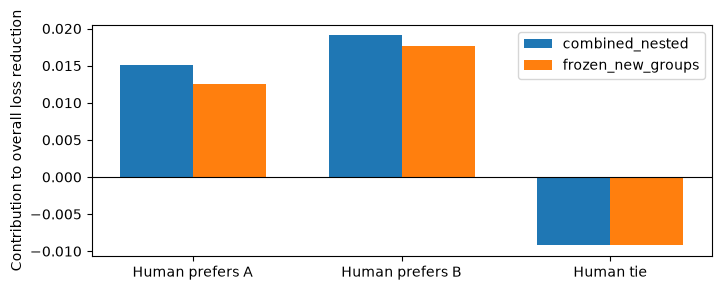

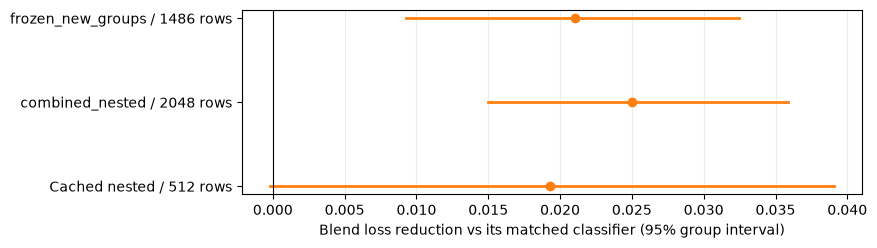

Native CUDA devices before repair: Available devices:
  (none)

Native CUDA devices after repair: Available devices:
  CUDA0: Tesla T4 (14911 MiB, 14806 MiB free)
  CUDA1: Tesla T4 (14911 MiB, 14806 MiB free)

Historical-cache identity/runtime gate: {'profile_rows': 32, 'profile_seconds': 38.65186396199999, 'mean_probability_difference': 0.021964193310207335, 'max_probability_difference': 0.16802273048218563, 'mean_limit': 0.01, 'max_limit': 0.1, 'projected_extra_seconds_with_margin': 2826.3473642111994, 'remaining_session_seconds': 4201.758108139038, 'identity_passed': False, 'throughput_passed': True}
The failed identity gate stopped scoring; the separate full cohort is re-scored uniformly.


In [3]:
cached=read('blend_results.json')['cohorts']['cached_judge']
display(pd.DataFrame([{'system':name,'rows':m['rows'],'log_loss':m['log_loss'],'accuracy':m['accuracy'],
                      'tie_loss':m['class_loss'][2]} for name,m in cached['models'].items()]))
print('Cached outer-fold judge weights:',[round(x['judge_weight'],4) for x in cached['folds']])
points=[('Cached nested / 512 rows',cached['blend_gain_vs_classifier'])]
if (RESULTS/'expanded_results.json').exists():
    expanded=read('expanded_results.json')
    for cohort,row in expanded['cohorts'].items():
        print(cohort)
        display(pd.DataFrame([{'system':name,'rows':m['rows'],'log_loss':m['log_loss'],
                              'accuracy':m['accuracy'],'tie_loss':m['class_loss'][2]}
                             for name,m in row['models'].items()]))
        points.append((cohort+' / '+str(row['rows'])+' rows',row['contrasts']['blend']))
    print('Runtime assessment:',expanded['runtime'])
    channel_rows=[]
    for cohort,row in expanded['cohorts'].items():
        for name,m in row['models'].items():
            d=m['loss_decomposition']
            channel_rows.append({'cohort':cohort,'system':name,
                'binary_tie_loss':d['binary_tie_log_loss'],
                'conditional_winner_contribution':d['conditional_winner_contribution'],
                'conditional_winner_accuracy':d['conditional_winner_accuracy']})
    display(pd.DataFrame(channel_rows))
    print('Conditional winner accuracy describes human-decisive rows only; no deployed routing uses labels.')
    fig,ax=plt.subplots(figsize=(8,3))
    x=np.arange(3);width=.35
    for index,(cohort,row) in enumerate(expanded['cohorts'].items()):
        contributions=row['contrasts']['blend']['weighted_class_contributions']
        ax.bar(x+(index-.5)*width,contributions,width,label=cohort)
    ax.set_xticks(x,['Human prefers A','Human prefers B','Human tie'])
    ax.axhline(0,color='black',linewidth=.8);ax.set_ylabel('Contribution to overall loss reduction')
    ax.legend();save(fig,'ensemble_class_contributions')
else:
    print('Uniform current-runtime validation is pending; historical judge outputs will not be pooled with new outputs.')
fig,ax=plt.subplots(figsize=(8,max(2.4,.8*len(points))))
for index,(label,result) in enumerate(points):
    lo,hi=result['interval_95']
    ax.plot([lo,hi],[index,index],linewidth=2,color='C1')
    ax.scatter(result['gain'],index,color='C1',zorder=3)
ax.set_yticks(range(len(points)),[label for label,_ in points])
ax.axvline(0,color='black',linewidth=.8);ax.grid(axis='x',alpha=.25)
ax.set_xlabel('Blend loss reduction vs its matched classifier (95% group interval)')
save(fig,'ensemble_gains')
if (RESULTS/'runtime_diagnostic_results.json').exists():
    runtime=read('runtime_diagnostic_results.json')
    print('Native CUDA devices before repair:',runtime['hardware']['devices_before'])
    print('Native CUDA devices after repair:',runtime['hardware']['devices_after'])
    print('Historical-cache identity/runtime gate:',runtime['gate'])
    print('The failed identity gate stopped scoring; the separate full cohort is re-scored uniformly.')


## E01 and H42: verified measurement and a stopped conditional experiment

The actual CUDA probe compares parameter changes with optimizer skip flags and
resumes checkpointed counters, scaler and scheduler. It uses a tiny deterministic
dataset; it does not prove bitwise reproduction of every stochastic training
pipeline. H42 stopped at its declared calibration gate without anchor training.


In [4]:
probe=read('instrumentation_results.json')
assert probe['passed']
display(pd.DataFrame([{'rank':rank['rank'],'run':run['name'],**run['counts']}
                      for rank in probe['ranks'] for run in rank['runs']]))
print('Actual CUDA software:',probe['software'])
print('Probe session:',probe['session_summary'])
print('Original training was cu128; this runtime is cu130. H03 is stateful continuation, without bitwise-equivalence claims.')
print('H42 calibration gate passed:',cal['cohorts']['paired_pilot']['h42_gate']['calibration_resolves_deficit'])


,rank,run,cycles,accepted_updates,skipped_updates,processed_tokens,accepted_tokens,processed_rows,accepted_rows,processed_unique_rows,accepted_unique_rows,processed_class_counts,accepted_class_counts,last_global_step
0,0,continuous,5,4,1,80,64,20,16,20,16,"[8, 8, 4]","[7, 6, 3]",5
1,0,resumed,5,4,1,80,64,20,16,20,16,"[8, 8, 4]","[7, 6, 3]",5
2,1,continuous,5,4,1,80,64,20,16,20,16,"[6, 6, 8]","[5, 5, 6]",5
3,1,resumed,5,4,1,80,64,20,16,20,16,"[6, 6, 8]","[5, 5, 6]",5


Actual CUDA software: {'torch': '2.11.0+cu130', 'transformers': '5.22.1', 'accelerate': '1.15.0', 'peft': '0.21.2'}
Probe session: {'exit_code': 0, 'session_seconds': 55.01853656768799}
Original training was cu128; this runtime is cu130. H03 is stateful continuation, without bitwise-equivalence claims.
H42 calibration gate passed: True


## H03: stateful training exposure

Continue selected checkpoint 800 toward the original one-epoch endpoint. Report
new accepted exposure separately from unknown historical accepted exposure. Fixed
final model is primary; training minibatch loss, selection loss and final calibrated
development loss have different data/postprocessing and must not be conflated.


,calibration,system,rows,log_loss,accuracy,tie_auc
0,temperature,classifier,5746,0.968872,0.527323,0.667578
1,temperature,continued,5746,0.954069,0.537939,0.679019
2,nested_selected,classifier,5746,0.967740,0.532022,0.667413
3,nested_selected,continued,5746,0.954419,0.539332,0.678252


,rank,cycles,accepted_updates,skipped_updates,processed_tokens,accepted_tokens,processed_rows,accepted_rows,processed_unique_rows,accepted_unique_rows,processed_class_counts,accepted_class_counts,last_global_step
0,0,638,638,0,5938718,5938718,10196,10196,10196,10196,"[3581, 3454, 3161]","[3581, 3454, 3161]",1438
1,1,638,638,0,5889868,5889868,10196,10196,10196,10196,"[3515, 3537, 3144]","[3515, 3537, 3144]",1438


Coverage: {'processed': {'unique_rows': 20392, 'unique_groups': 18991, 'total_visits': 20392, 'maximum_visits': 1}, 'accepted': {'unique_rows': 20392, 'unique_groups': 18991, 'total_visits': 20392, 'maximum_visits': 1}}
Actual resume-state check and logical update counts: {'verified': True, 'parent_nominal_step': 800, 'parent_scheduler_position': 796, 'parent_amp_scale': 4096.0, 'new_accepted_updates_global': 638, 'parent_accepted_updates_inferred': 796, 'combined_accepted_updates_inferred': 1434, 'note': 'Parent accepted count is reconstructed under pinned accepted-only LambdaLR semantics; new counts use direct skip flags. Historical row/token exposure was not logged. DDP ranks are not summed for logical optimizer updates.'}
Training result: {'initial_step': 800, 'final_step': 1438, 'epochs_completed': 1.0, 'training_seconds': 14812.441299382, 'development_prediction_seconds': 3481.299346444999, 'stopped_for_time': False, 'stopped_for_plateau': False}
Identity guards: [{'rank': 0, 'ro

,classifier,continued
decision_disagreement,0.354492,0.242188
mean_probability_l1,0.252973,0.215371
second_position_advantage,0.088290,-0.007554


Matched raw-order disagreement reduction: {'gain': 0.1123046875, 'interval_95': [0.08308409738965133, 0.14397980768038665], 'groups': 990, 'rows': 1024, 'replicates': 2000}
Original-order packing slices (observational, global OOF calibration):


,slice,rows,classifier_loss,continued_loss,gain
0,unclipped,4594,0.954348,0.939146,0.015202
1,any_field_clipped,1152,1.026795,1.013582,0.013213


Peak allocated GPU bytes (rank 0): 7792161280


,system,class,loss,recall
0,classifier,A,0.948396,0.559821
1,classifier,B,0.960497,0.560305
2,classifier,Tie,1.001286,0.454085
3,continued,A,0.898423,0.608175
4,continued,B,0.910061,0.609669
5,continued,Tie,1.065677,0.379155


Primary matched gain and group interval: {'gain': 0.014803277227999973, 'interval_95': [0.010945489367988295, 0.018368393990048196], 'groups': 5211, 'rows': 5746, 'replicates': 2000, 'weighted_class_contributions': [0.017446129233436504, 0.017247944884855232, -0.01989079689029176]}


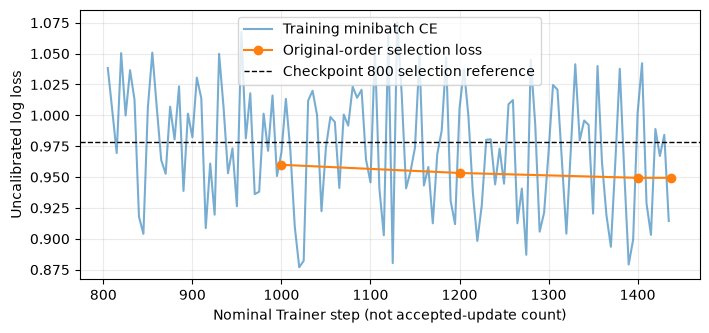

Constant baselines, fit using training labels only:


,baseline,rows,log_loss,accuracy,macro_f1
0,uniform,5746,1.098612,0.349112,0.172515
1,training_prior,5746,1.097216,0.349112,0.172515
2,hard_majority,5746,17.984688,0.349112,0.172515


Exact unsmoothed log loss is infinite on any wrong hard prediction. The finite diagnostic uses the common 1e-12 clipping convention; training-prior probabilities give the same constant class prediction with meaningful finite log loss.
Accuracy uses argmax; equal maxima choose the first class A, then B, then tie.


,rows,any_field_cut_fraction,prompt_cut_fraction,answer_cut_fraction,mean_row_content_retained_fraction,corpus_content_retained_fraction,raw_content_tokens,retained_content_tokens
training_partition,45985.0,0.196455,0.071545,0.158291,0.937350,0.800896,30640507.0,24539868.0
full_development,5746.0,0.200487,0.072746,0.165680,0.935076,0.797221,3892233.0,3102969.0
order_reference,1024.0,0.196289,0.066406,0.165039,0.937090,0.819474,687071.0,563037.0
ensemble_combined,2048.0,0.199707,0.073242,0.166504,0.933917,0.800018,1399093.0,1119299.0


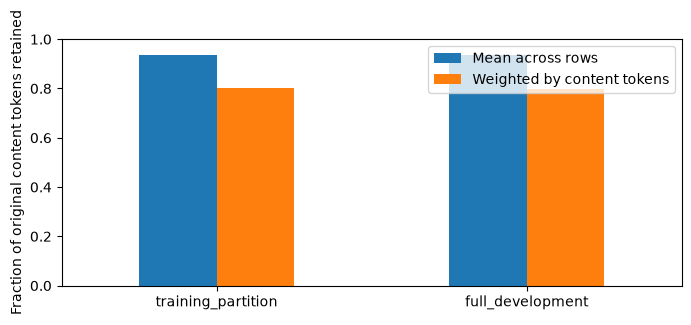

Reuse EDA content-token accounting under unchanged original-order 1024-token packing; marker tokens excluded. Cached labels checked for row alignment only.
Packing/tokenizer are unchanged during continuation; these descriptors are shared by both classifiers.
Native judge retention/order/memory coverage: {'rows': 2048, 'truncated_rows': 697, 'truncated_fraction': 0.34033203125, 'mean_packed_tokens': 745.3369140625, 'prompt_overhead_tokens': 239, 'both_orders_measured': False, 'order_disagreement': None, 'order_note': 'The single-order source summary uses zero as an order-flip placeholder; it is not measured invariance.', 'gpu_count': 2, 'physical_memory_MiB_per_gpu': 15360, 'peak_allocated_bytes': None, 'memory_note': 'Two-T4 execution succeeded; peak native GPU allocation was not captured. Capacity is not peak usage.'}


In [5]:
if (RESULTS/'exposure_results.json').exists():
    training=read('exposure_results.json')
    display(pd.DataFrame([{'calibration':family,'system':name,'rows':m['rows'],
                          'log_loss':m['log_loss'],'accuracy':m['accuracy'],'tie_auc':m['tie_auc']}
                         for family,row in training['cohorts'].items() for name,m in row['models'].items()]))
    display(pd.DataFrame(training['exposure']['rank_summaries']))
    print('Coverage:',training['exposure']['coverage'])
    print('Actual resume-state check and logical update counts:',training['exposure']['resume_state_guard'])
    print('Training result:',{k:training['summary'][k] for k in ['initial_step','final_step','epochs_completed',
                              'training_seconds','development_prediction_seconds','stopped_for_time','stopped_for_plateau']})
    print('Identity guards:',training['starting_identity'])
    print('Finite exported weights:',training['weight_audit'])
    print('Raw field token lengths (training):',training['summary']['train_diagnostics'])
    print('Raw field token lengths (development):',training['summary']['final_diagnostics'])
    print('Historical deployed calibration reference:',training['historical_deployed_reference'])
    display(pd.DataFrame({key:training['matched_order'][key] for key in ['classifier','continued']}))
    print('Matched raw-order disagreement reduction:',training['matched_order']['disagreement_reduction'])
    print('Original-order packing slices (observational, global OOF calibration):')
    display(pd.DataFrame([{'slice':name,'rows':row['rows'],
                          'classifier_loss':row['models']['classifier']['log_loss'],
                          'continued_loss':row['models']['continued']['log_loss'],
                          'gain':row['contrasts']['continued']['gain']}
                         for name,row in training['retention_slices'].items()]))
    print('Peak allocated GPU bytes (rank 0):',training['summary']['peak_gpu_bytes'])
    primary=training['cohorts']['temperature']
    display(pd.DataFrame([{'system':name,'class':label,'loss':m['class_loss'][index],
                          'recall':m['class_recall'][index]}
                         for name,m in primary['models'].items()
                         for index,label in enumerate(['A','B','Tie'])]))
    print('Primary matched gain and group interval:',primary['contrasts']['continued'])
    progress_path=HEAVY/'jobs/exposure/output/exposure/training_progress.jsonl'
    progress=[json.loads(line) for line in progress_path.read_text().splitlines()]
    train=[x for x in progress if 'loss' in x];validation=[x for x in progress if 'eval_log_loss' in x]
    fig,ax=plt.subplots(figsize=(8,3.5))
    ax.plot([x['step'] for x in train],[x['loss'] for x in train],alpha=.6,label='Training minibatch CE')
    if validation:
        ax.plot([x['step'] for x in validation],[x['eval_log_loss'] for x in validation],'o-',label='Original-order selection loss')
    ax.axhline(training['selection_reference']['raw_original_order_log_loss'],
               color='black',linestyle='--',linewidth=1,label='Checkpoint 800 selection reference')
    ax.set_xlabel('Nominal Trainer step (not accepted-update count)');ax.set_ylabel('Uncalibrated log loss')
    ax.legend();ax.grid(alpha=.25);save(fig,'training_curve')
else:
    snapshot=RESULTS/'live_progress_exposure.json'
    print('Final H03 quality is pending.')
    if snapshot.exists():display(json.loads(snapshot.read_text()))
if (RESULTS/'packing_diagnostics.json').exists():
    packing=read('packing_diagnostics.json')
    print('Constant baselines, fit using training labels only:')
    display(pd.DataFrame([{'baseline':name,'rows':m['rows'],'log_loss':m['log_loss'],
                          'accuracy':m['accuracy'],'macro_f1':m['macro_f1']}
                         for name,m in packing['constant_baselines']['models'].items()]))
    print(packing['constant_baselines']['hard_majority_note'])
    print(packing['constant_baselines']['prediction_rule'])
    table=pd.DataFrame(packing['cohorts']).T
    display(table)
    show=table.loc[['training_partition','full_development'],
                   ['mean_row_content_retained_fraction','corpus_content_retained_fraction']]
    ax=show.plot.bar(figsize=(8,3.2),rot=0,ylim=(0,1))
    ax.set_ylabel('Fraction of original content tokens retained')
    ax.legend(['Mean across rows','Weighted by content tokens'])
    save(ax.figure,'content_retention')
    print(packing['method'])
    print('Packing/tokenizer are unchanged during continuation; these descriptors are shared by both classifiers.')
    print('Native judge retention/order/memory coverage:',packing['native_judge'])


## Resources and versioned handoff

Completion requires actual finished/stopped jobs, final evidence, this executed
notebook and sealed v2/v3 snapshots. Read the final report and audit; a green
notebook or a successful pilot is insufficient by itself.


In [6]:
audit_path=RESULTS/'terminal_audit.json'
if audit_path.exists():
    display(json.loads(audit_path.read_text()))
else:
    print('Terminal resource audit pending; goal remains active.')
if (RESULTS/'decisions.json').exists():
    print('Adoption decisions:',read('decisions.json'))
if (RESULTS/'research_candidate.json').exists():
    candidate=read('research_candidate.json')
    print('Frozen research reference:',{key:candidate[key] for key in
          ['source_kernel','version_number','final_step','temperature','officially_verified']})
display(pd.DataFrame([{'version':v['number'],'state':v['state'],'members':len(v['item_ids']),
                      'focus':v['focus_ids']} for v in registry['versions']]))
print('Standalone figures:',FIGURES)


{'checked_at': '2026-11-04T04:24:47.620991+00:00',
 'all_recorded_jobs_terminal': True,
 'jobs': [{'job': 'instrumentation',
   'kernel': 'arseniytrushin/llm-preference-span-002-exposure-probe',
   'version': 1,
   'status': 'COMPLETE',
   'observed_at': '2026-11-04T04:23:58.969290+00:00',
   'notebook_sha256': '72f4d0e2edb740a36162992423375d188efc01a43fbca6abfb223dac7d584c8d',
   'max_session_seconds': 900,
   'remote_source_matches': True,
   'remote_cell_sources_sha256': '878808740916bc77ced21c7f2abd7be4936972a827e834703dbb28396066ef61'},
  {'job': 'exposure',
   'kernel': 'arseniytrushin/llm-preference-span-002-exposure',
   'version': 1,
   'status': 'COMPLETE',
   'observed_at': '2026-11-04T04:24:00.928511+00:00',
   'notebook_sha256': 'c51fefdf96de06bdc414e964ff6628e1b98c801c6ad7f530063c29c6fd0279e2',
   'max_session_seconds': 21600,
   'remote_source_matches': True,
   'remote_cell_sources_sha256': '430f619503fa195c0b78c7d9b44c8a472c247ff3934adee7bae82f2f34b81be6'},
  {'job': '

Adoption decisions: {'span': 2, 'generated_at': '2026-11-04T00:09:31.725751+00:00', 'all_focus_measurements_complete': True, 'tasks': {'H40': {'experiment_complete': True, 'contrast': {'gain': 0.001132495700997212, 'interval_95': [-0.0005643220873635243, 0.0029542135675369556], 'groups': 5211, 'rows': 5746, 'replicates': 2000, 'weighted_class_contributions': [0.013293043928159543, 0.013026247452813422, -0.025186795679975754]}, 'adopted': False, 'reason': 'Primary nested estimate is uncertain; the best individual family is not the selected-procedure estimate.'}, 'E01': {'experiment_complete': True, 'passed': True, 'reason': 'Actual two-rank CUDA overflow, parameter-change and resume checks passed.'}, 'H42': {'experiment_complete': True, 'gpu_anchor_training_executed': False, 'gate': {'overall_loss_gap': -0.00015099503594040442, 'tie_class_loss_gap': 0.0015366018961533445, 'calibration_resolves_deficit': True, 'interpretation': 'Predeclared practical stopping rule, not an equivalence tes

,version,state,members,focus
0,1,closed,41,"[E00, H01, H09, H04, H11]"
1,2,closed,39,"[H40, E01, H03, H37, H42]"
2,3,active,37,[]
3,4,draft,0,[]


Standalone figures: /home/tarstars/database/llm_classification_finetuning/runs/span_002/figures
